In [1]:
import pandas as pd
import numpy as np

# Import clean data
path = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/Data%20files/module_5_auto.csv'
df = pd.read_csv(path)
# df = pd.read_csv(path, encoding='utf-8')

df.to_csv('module_5_auto.csv')


# _get_numeric_data() 是 pandas DataFrame 的一个方法，返回一个只包含数值型列（int、float 等）的新 DataFrame，字符串列（如 make、fuel-type、body-style）、布尔列等都会被自动剔除。
# df = df._get_numeric_data() 用筛选结果覆盖原来的 df，后续所有操作都基于这个纯数值的数据集。
df=df._get_numeric_data()
df.head()


import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

# DistributionPlot，用于对比两条数据的概率密度分布曲线（典型用法：真实价格 vs 模型预测价格的分布对比）
# RedFunction：第一条要绘制的数据（通常画成红色，本 lab 中常是真实值，如 y_train 或 y_test）
# BlueFunction：第二条要绘制的数据（蓝色，通常是模型预测值，如 yhat_train）
# RedName / BlueName：两条曲线的图例标签文字
# Title：图表标题
# 用 seaborn 的 kdeplot（核密度估计图，Kernel Density Estimate）绘制第一组数据：
# DE 是对数据分布的平滑连续估计，相当于平滑版的直方图，能直观看出价格的分布形状（峰值位置、宽度、偏态）
# color="r" 红色；label=RedName 设置图例文字
# 返回值 ax1 是 matplotlib 的坐标轴对象，供下一条曲线共用
# 关键在 ax=ax1：显式指定画到 ax1 上。如果不传这个参数，seaborn 可能自动新建画布，两条曲线就分开了。这样两条曲线叠在一起，才能直接对比。
def DistributionPlot(RedFunction, BlueFunction, RedName, BlueName, Title):
    width = 12
    height = 10
    plt.figure(figsize=(width, height))

    ax1 = sns.kdeplot(RedFunction, color="r", label=RedName)
    ax2 = sns.kdeplot(BlueFunction, color="b", label=BlueName, ax=ax1)

    plt.title(Title)
    plt.xlabel('Price (in dollars)')
    plt.ylabel('Proportion of Cars')
    plt.show()
    plt.close()

# xtrain / xtest：训练集/测试集的特征值（本 lab 中是 horsepower 这一列）
# y_train / y_test：对应的真实价格
# lr：已训练好的线性回归模型对象（如 poly = LinearRegression()）
# poly_transform：多项式特征变换器（如 pr = PolynomialFeatures(degree=5)）
# 第二个可视化辅助函数 PollyPlot，用于把训练数据点、测试数据点和多项式回归模型的预测曲线画在同一张图上，直观展示模型的拟合效果
# 取训练集和测试集中特征的最大值/最小值，确定横轴要覆盖的完整范围——这样画出的预测曲线能同时覆盖两类数据点的区域。
# 绘制训练数据：'ro' 是格式字符串——r = 红色，o = 圆点标记。即红色圆点 (x=马力， y=价格)，图例标注 "Training Data"。
# 绘制测试数据：'go' = 绿色圆点，图例 "Test Data"。红/绿两色区分了模型“见过”和“没见过”的数据

def PollyPlot(xtrain, xtest, y_train, y_test, lr,poly_transform):
    width = 12
    height = 10
    plt.figure(figsize=(width, height))


    #training data
    #testing data
    # lr:  linear regression object
    #poly_transform:  polynomial transformation object

    xmax=max([xtrain.values.max(), xtest.values.max()])

    xmin=min([xtrain.values.min(), xtest.values.min()])

    x=np.arange(xmin, xmax, 0.1)


    plt.plot(xtrain, y_train, 'ro', label='Training Data')
    plt.plot(xtest, y_test, 'go', label='Test Data')
    # x.reshape(-1, 1)：把一维数组 x 变成形状 (n, 1) 的二维列向量——sklearn 要求特征输入是二维的
    # poly_transform.fit_transform(...)：对网格点做多项式特征展开
    # 如 degree=5 时生成 [x, x², x³, x⁴, x⁵]），必须与训练模型时用的变换器参数（degree）一致，否则维度不匹配
    # 用训练好的模型对每个网格点预测价格
    # plt.plot(x, ...)：把“马力 → 预测价格”画成一条线（默认蓝色实线），即模型的预测函数曲线
    plt.plot(x, lr.predict(poly_transform.fit_transform(x.reshape(-1, 1))), label='Predicted Function')
    # 固定纵轴范围为 -10000 到 60000 美元。这一步很关键：degree 高的多项式在数据边界外会剧烈震荡甚至发散（例如 200+ 马力区域预测值飞出几千甚至几万美元），固定 y 轴范围能防止图形被极端值撑爆，让我们清楚看到曲线“失控”的样子。
    plt.ylim([-10000, 60000])
    plt.ylabel('Price')
    # plt.legend() 的作用是显示图例
    plt.legend()


# 训练集与测试集
#要预测的车价
y_data = df['price']
# 除了车价中的所有列
x_data=df.drop('price',axis=1)

# 这是 Part 1（训练与测试）中数据集划分的核心代码。
# 从 sklearn 的 model_selection 模块导入 train_test_split 函数——这是 sklearn 官方提供的、把数据集随机拆分为训练集/测试集的标准工具。
# x_data, y_data：待划分的特征和目标。函数内部会按同样的随机顺序打乱两者的行，保证特征与标签的对应关系不被破坏
# test_size=0.10：10% 的样本划入测试集，其余 90% 划入训练集
# random_state=1：随机种子。固定种子后，每次运行得到的划分结果完全一致（可复现）。这是教学/作业中的关键设置——否则每次运行 notebook 的指标都会变，无法对齐参考答案
# 变量	        内容	        行数
# x_train	训练集特征	    90%
# x_test	测试集特征	    10%
# y_train	训练集目标（价格）	90%
# y_test	测试集目标（价格）	10%

 # 易错点：x_train 必须配 y_train，x_test 必须配 y_test，写错配对会导致模型学到错误对应关系。
#  .shape 返回 (行数, 列数)，[0] 取行数即样本数
# 用来验证划分比例：汽车数据集共 201 行，10% 测试 → 输出大约 test: 21、training: 180（sklearn 用 ceil 计算测试集数量，所以是 21 而非 20）

from sklearn.model_selection import train_test_split

#专门划分训练集和测试集用的
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.10, random_state=1)


print("number of test samples :", x_test.shape[0])
print("number of training samples:",x_train.shape[0])


# 为什么要划分？
# 训练集用来让模型“学习”规律，测试集（模型从未见过的数据）用来模拟真实场景下的表现。如果直接在训练数据上评估，模型可能只是背下了答案（过拟合），分数虚高；
# 第 1 步：划分数据（10% 留作测试）
# 第 2 步：用 90% 的训练集"喂"给模型学习 → 得到模型
# 第 3 步：把模型放进测试集"考试"



number of test samples : 21
number of training samples: 180


In [2]:
x_train1, x_test1, y_train1, y_test1 = train_test_split(x_data, y_data, test_size=0.4, random_state=0)
print("number of test samples :", x_test1.shape[0])
print("number of training samples:",x_train1.shape[0])


# sklearn：scikit-learn 机器学习库的导入名，Python 中最常用的机器学习工具包
# sklearn.linear_model：sklearn 下的线性模型子模块，收录各种线性回归/分类算法
# from ... import LinearRegression：只把其中的普通最小二乘线性回归类（Ordinary Least Squares）导入当前命名空间，之后可以直接写 LinearRegression() 而不用写全路径
from sklearn.linear_model import LinearRegression
# 创建模型对象
lre=LinearRegression()
# 用训练集学习：只看1个特征 horsepower
#  在测试集上算 R²，评估泛化能力
# 在fit里面 x表示特征（模型的输入，必须是二维的，形状 (样本数, 特征数)），y表示目标（模型要学习预测的答案，一维，形状 (样本数,)）
# 通俗易懂的话，X表示题目，Y表示题目的对应答案，我们对着题目和答案，把规律总结出来，从中学到“马力越大价格越高”这种规律，相当于上课
lre.fit(x_train[['horsepower']], y_train)
# x表示特征，y表示真实答案
# 通俗易懂，再给你一道新题目，给你xtest，根据你上面总结出来的规律你得出你的y（就是yhat预测值，模型自己算的），然后再与这里的y_test标准答案对比，越接近，说明这个规律预测的越好
lre.score(x_test[['horsepower']], y_test)
# 这下面就相当于用原题来获得答案，那肯定效果好，这不具有意义
lre.score(x_train[['horsepower']], y_train)


number of test samples : 81
number of training samples: 120


0.6619724197515104

In [3]:
x_train1, x_test1, y_train1, y_test1 = train_test_split(x_data, y_data, test_size=0.4, random_state=0)
lre.fit(x_train1[['horsepower']],y_train1)
lre.score(x_test1[['horsepower']],y_test1)


# sklearn.model_selection：sklearn 中负责模型选择与评估的子模块（之前用的 train_test_split 也来自这里）
# from ... import cross_val_score：导入交叉验证评分函数
from sklearn.model_selection import cross_val_score

# Rcross和上面比起来更慢，但是效果好
# lre 要评估的线性回归模型（之前创建的 lre = LinearRegression()）
# 特征：全部 201 辆车的马力（注意是 x_data 不是 x_train——交叉验证不需要你手动划分，它自己切）
# 目标：全部 201 个真实车价
# 切成 4 折（4-fold） 数据总共 201 行，每折约 50 个样本。
# 内部发生了什么
# 第1轮: 用第2,3,4份训练 → 在第1份上测 → R²_1
# 第2轮: 用第1,3,4份训练 → 在第2份上测 → R²_2
# 第3轮: 用第1,2,4份训练 → 在第3份上测 → R²_3
# 第4轮: 用第1,2,3份训练 → 在第4份上测 → R²_4
Rcross = cross_val_score(lre, x_data[['horsepower']], y_data, cv=4)
# Rcross 是一个含 4 个 R² 分数的数组  array([0.774, 0.514, 0.758, 0.714], dtype=float64)
Rcross
# mean（平均分）：比单次 train_test_split 的分数更可靠的整体表现估计
# std（标准差）：分 数波动大 → 模型表现不稳定，或数据分布不均匀
print("The mean of the folds are", Rcross.mean(), "and the standard deviation is" , Rcross.std())

# cross_val_score(lre, x_data[['horsepower']], y_data, cv=4, scoring='neg_mean_squared_error') 换个评价指标，不用R平方
# 用它时前面要乘 -1 取回真正的 MSE，返回的是负均方误差 注意：真正的 MSE 永远 ≥ 0 负号是sklearn 自己加的“包装”
# sklearn 的设计哲学是：所有评分指标统一“越大越好”；但 MSE 的性质是“越小越好”，和这个哲学冲突了。于是 sklearn 的做法是：返回 MSE 的相反数，并给它起名
# 预测质量	真实 MSE	    sklearn 返回的“负 MSE”
# 很好	    0.1	        -0.1（较大，接近 0）
# 很差	    500	        -500（较小）
-1 * cross_val_score(lre,x_data[['horsepower']], y_data,cv=4,scoring='neg_mean_squared_error')



The mean of the folds are 0.522009915042119 and the standard deviation is 0.2911839444756029


array([20254142.84026702, 43745493.2650517 , 12539630.34014931,
       17561927.7224759 ])

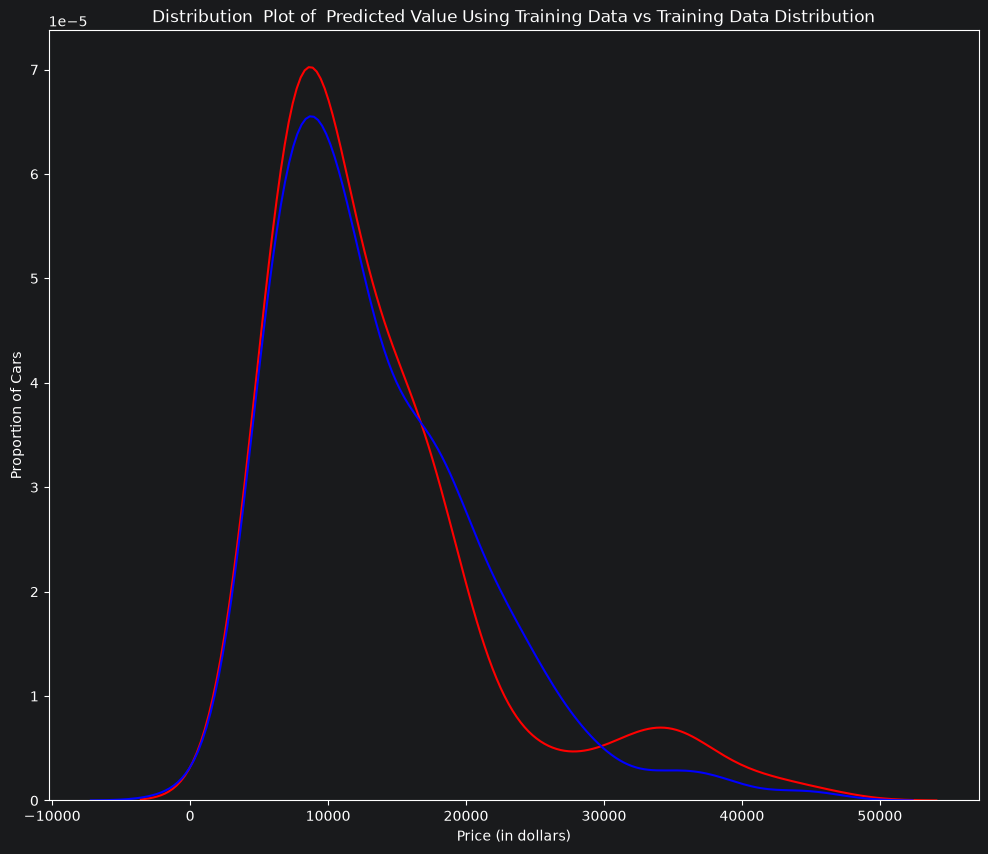

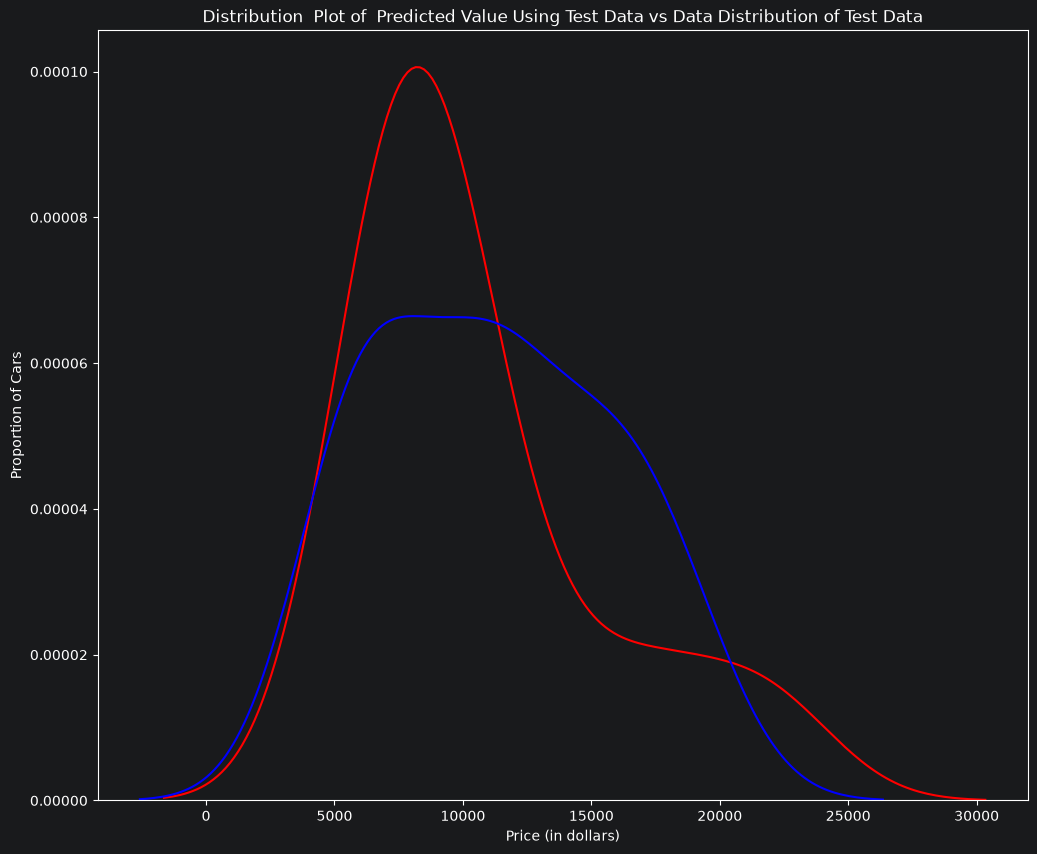

Predicted values: [10872.42511539  8627.52078227  9628.84118509  9062.17889374]
True values: [ 9549.  6229. 10245.  7295.]


Text(3, 0.75, 'Maximum R^2 ')

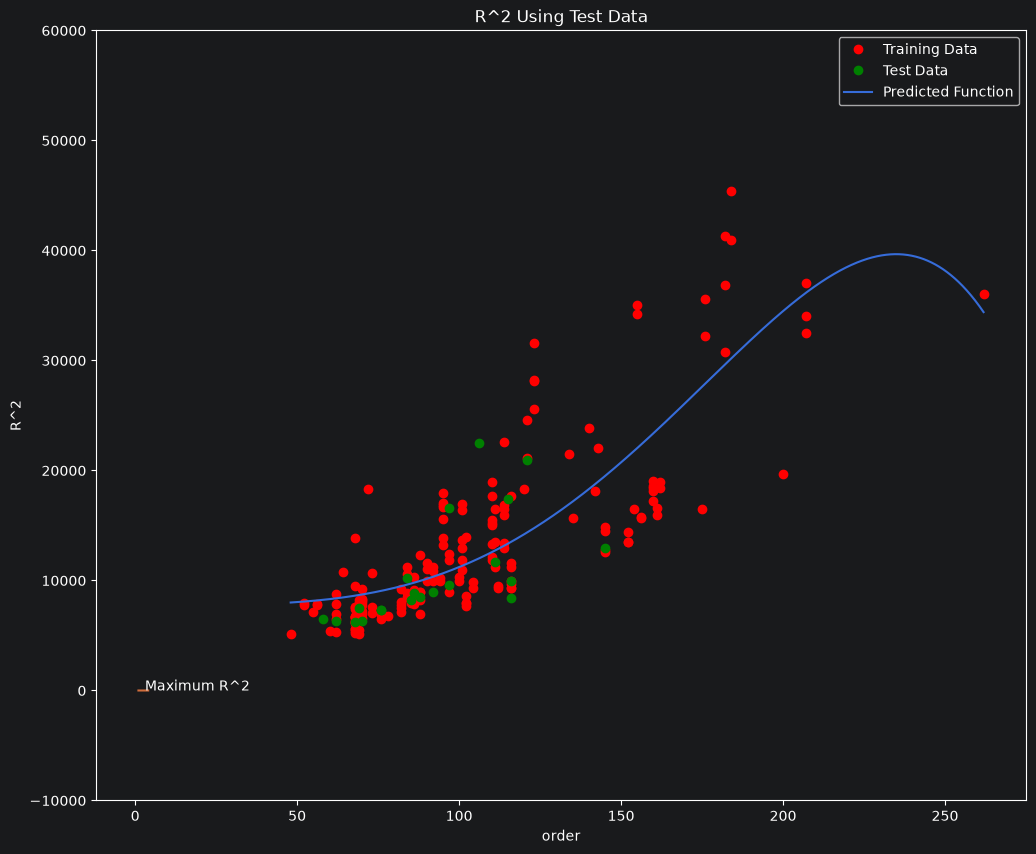

In [4]:
Rc=cross_val_score(lre,x_data[['horsepower']], y_data,cv=2)
Rc.mean()

# cross_val_predict：交叉验证预测函数——注意和 cross_val_score 只差两个字，功能却不同
# cross_val_predict 回答：“模型对每一辆车的预测分别是多少？”（可用于画图、分析哪些车预测得差）
from sklearn.model_selection import cross_val_predict
# yhat 里的预测值不是来自一个统一的模型——第 1 个样本的预测来自第 1 轮的模型，第 100 个样本的预测来自第 3 轮的模型。4 个模型参数略有差异，所以这组预测适合做评估和可视化，不适合直接当成“某个最终模型”的输出去部署
# 新建 4 个同类型模型，分别用 3/4 的数据训练，各自预测自己没见过的那 1/4 数据，最后把所有预测值按原顺序拼成一整个数组
# cross_val_predict(cv=4) 内部大致等价于：
# model1 = LinearRegression()  # 新建，用第2,3,4份数据训练
# model2 = LinearRegression()  # 新建，用第1,3,4份数据训练
# model3 = LinearRegression()  # 新建，用第1,2,4份数据训练
# model4 = LinearRegression()  # 新建，用第1,2,3份数据训练
yhat = cross_val_predict(lre,x_data[['horsepower']], y_data,cv=4)
yhat[0:5]


# 多元线性回归
lr = LinearRegression()
lr.fit(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_train)

yhat_train = lr.predict(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])
yhat_train[0:5]
yhat_test = lr.predict(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])
yhat_test[0:5]

# 直接调用函数，用于画图
# 用于对比两条数据的概率密度分布曲线（典型用法：真实价格 vs 模型预测价格的分布对比）
Title = 'Distribution  Plot of  Predicted Value Using Training Data vs Training Data Distribution'
DistributionPlot(y_train, yhat_train, "Actual Values (Train)", "Predicted Values (Train)", Title)

Title='Distribution  Plot of  Predicted Value Using Test Data vs Data Distribution of Test Data'
DistributionPlot(y_test,yhat_test,"Actual Values (Test)","Predicted Values (Test)",Title)


# 把“直线拟合不了的数据”变成“直线能拟合的数据”。
# 普通线性回归只能拟合直线：
from sklearn.preprocessing import PolynomialFeatures

# 但价格和马力的真实关系往往是曲线。多项式特征的做法是：人为构造新列，比如 degree=3 时把 1 列 horsepower 变成 3 列
# horsepower	x²	x³
# 100	10000	1,000,000
# 150	22500	3,375,000
# 然后依然用普通的线性回归去拟合
# 对x来说这是直线方程，但对原始 horsepower 来说就是一条曲线——这就是“多项式回归”的本质：特征变了，模型没变（所以 notebook 后面还是用 LinearRegression）。
# 变换前：特征只有 1 个
# horsepower	price
# 100	13500
# 150	16500
# 200	18000

# 变换后，变成三个特征  其实就是构造新的列
# horsepower（原特征 x）	x²（新特征）	x³（新特征）	price
# 100	10000	1,000,000	13500
# 150	22500	3,375,000	16500
# 200	40000	8,000,000

# 总结：偷偷把表格加工成三列（x、x²、x³）再给他——他的工作方式一点没变，但他算出的结果已经能画出曲线了
# 回归模型（LinearRegression）从头到尾都是线性的，“弯”是喂给它的特征造出来的。

# 数学上：polyfit ≡ PolynomialFeatures + LinearRegression，殊途同归，都是解决同一个方程问题
# 定位上：polyfit 是 numpy 给的“快速拟合计算器”，适合一行画曲线；sklearn 那套是“可训练、可评估、可调参、可防过拟合”的完整机器学习流水线——本 lab 研究过拟合和 Ridge 正则化，必须用它

# 这个 lab 的主题是模型评估与优化——要反复做 train/test 划分、交叉验证、调 degree、加 Ridge 正则化、网格搜索。
# 	np.polyfit	PolynomialFeatures + LinearRegression
# 风格	一行出结果，返回系数数组	面向对象：fit / predict / score
# 预测接口	p(x_new) 手动调用	poly.predict(x_pr)，统一 API
# 评估指标	没有内置 R²，要手写	score() 直接给 R²
# 多特征支持	❌ 只能处理一维 x	✅ 任意多列，还能生成交互项（horsepower×engine-size）
# 进 sklearn 生态	❌ 没法接	✅ 能接 Pipeline、cross_val_score、GridSearchCV
# 正则化	❌ 没有防过拟合手段	✅ 配 Ridge 后就是 Part 3 的内容


# 场景	                    选谁
# 拿到一组点，想画条趋势线	polyfit（更快更简单）
# 要评估模型“考试”能力、防止过拟合、调参数	sklearn 那套（polyfit 做不了）



# 创建变换器，指定最高次幂为5
pr = PolynomialFeatures(degree=5)
# 1列 → 6列 [1, x, x², x³, x⁴, x⁵]
# fit_transform 的含义
# fit：分析数据（确定要生成哪些列、列名等）
# transform：实际生成新特征矩阵
#注意！！！！为什么这里没有进行升维，没有x1*x2这种项，因为里面的参数只有一个horsepower，没有办法进行x1*x2
x_train_pr = pr.fit_transform(x_train[['horsepower']])
x_test_pr = pr.fit_transform(x_test[['horsepower']])
pr

# 还是那个普通线性回归
# 但喂进去的是多项式特征


#  选择A：喂 x_train（1列）
# poly.fit(x_train, y_train)
#  模型学到：price = b + w·hp          → 一条直线，R² 很低
#
#  选择B：喂 x_train_pr（6列）← notebook 的做法
# poly.fit(x_train_pr, y_train)
#  模型学到：price = b + w₁x + w₂x² + w₃x³ + w₄x⁴ + w₅x⁵  → 一条曲线

#喂给模型的数据用x_train_pr，训练出模型，也就是解出方程
poly = LinearRegression()
poly.fit(x_train_pr, y_train)

#预测也是用变换后的预测值
yhat = poly.predict(x_test_pr)
yhat[0:5]

print("Predicted values:", yhat[0:4])
# 输出：
# 90     9549.0      ← 90 是索引（这辆车在原始表中的行号）
# 135    11199.0
# 143    13860.0
# 160    7775.0
# Name: price, dtype: float64


print("True values:", y_test[0:4].values)
# 输出：
# [ 9549. 11199. 13860.  7775.]    ← 干干净净的数字

#画图
PollyPlot(x_train['horsepower'], x_test['horsepower'], y_train, y_test, poly,pr)
poly.score(x_train_pr, y_train)
poly.score(x_test_pr, y_test)

Rsqu_test = []

order = [1, 2, 3, 4]
for n in order:
    pr = PolynomialFeatures(degree=n)

    x_train_pr = pr.fit_transform(x_train[['horsepower']])

    x_test_pr = pr.fit_transform(x_test[['horsepower']])

    lr.fit(x_train_pr, y_train)

    Rsqu_test.append(lr.score(x_test_pr, y_test))

plt.plot(order, Rsqu_test)
plt.xlabel('order')
plt.ylabel('R^2')
plt.title('R^2 Using Test Data')
# 在坐标 (x=3, y=0.75) 处添加文字 "Maximum R²"——标注最高点出现的位置，提示读者最优 degree 在 3 附近。
plt.text(3, 0.75, 'Maximum R^2 ')


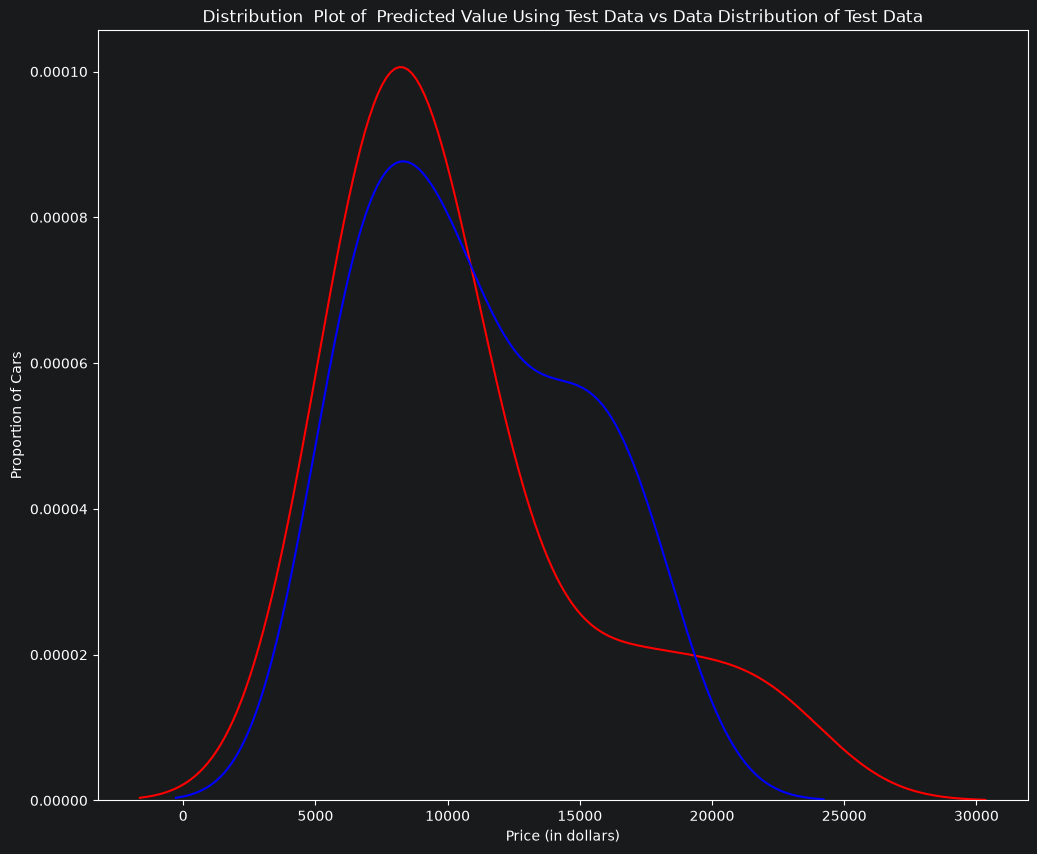

D:\pythonCourse\pythonCode\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 2.3800870451591558e-20.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


predicted: [11706.79578821  7760.00849553  9983.81298719  8907.90773469]
test set : [ 9549.  6229. 10245.  7295.]


  0%|          | 0/1000 [00:00<?, ?it/s, Test Score=0.366, Train Score=0.674]D:\pythonCourse\pythonCode\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 2.380087045159156e-19.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
  0%|          | 0/1000 [00:00<?, ?it/s, Test Score=0.366, Train Score=0.674]D:\pythonCourse\pythonCode\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 4.760174090318312e-19.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
  0%|          | 0/1000 [00:00<?, ?it/s, Test Score=0.365, Train Score=0.674]D:\pythonCourse\pythonCode\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7.140261135477467e-19.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
  0%|          | 0/1000 [00:00<

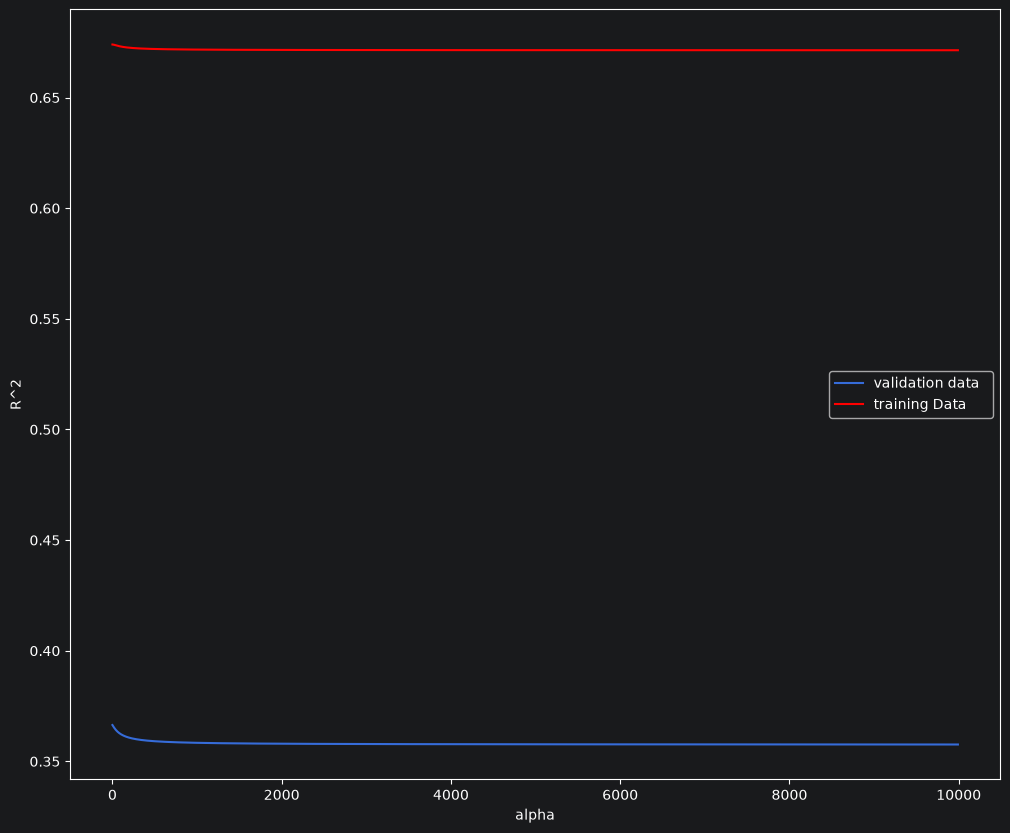

In [5]:
# 标准化
pr1=PolynomialFeatures(degree=2)

# powers_ =（powers_ 是"列清单"的转置视图——每行是一个列的配方，所以 11 个新增列在）
# [[0 0 0 0]   ①  1（截距列，全1）          [新增]
#  [1 0 0 0]   ②  x1 = horsepower          （原有）
#  [0 1 0 0]   ③  x2 = curb-weight         （原有）
#  [0 0 1 0]   ④  x3 = engine-size         （原有）
#  [0 0 0 1]   ⑤  x4 = highway-mpg         （原有）
#  [2 0 0 0]   ⑥  x1² = horsepower²        [新增]
#  [1 1 0 0]   ⑦  x1·x2                    [新增]
#  [1 0 1 0]   ⑧  x1·x3                    [新增]
#  [1 0 0 1]   ⑨  x1·x4                    [新增]
#  [0 2 0 0]   ⑩  x2²                      [新增]
#  [0 1 1 0]   ⑪  x2·x3                    [新增]
#  [0 1 0 1]   ⑫  x2·x4                    [新增]
#  [0 0 2 0]   ⑬  x3²                      [新增]
#  [0 0 1 1]   ⑭  x3·x4                    [新增]
#  [0 0 0 2]]  ⑮  x4²                      [新增]
# 升维
x_train_pr1=pr1.fit_transform(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])

x_test_pr1=pr1.fit_transform(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])

x_train_pr1.shape

# 建立模型、算出系数、里面传入升维后的训练集和价格训练集
poly1=LinearRegression().fit(x_train_pr1,y_train)

# 预测后，输出测试集的密度函数
yhat_test1=poly1.predict(x_test_pr1)

Title='Distribution  Plot of  Predicted Value Using Test Data vs Data Distribution of Test Data'

DistributionPlot(y_test, yhat_test1, "Actual Values (Test)", "Predicted Values (Test)", Title)

# Ridge 回归是什么
# 高维多项式特征容易导致过拟合（前面 Question 4 已经演示了）
# 引入 Ridge 回归，通过 L2 正则化压制系数大小，缓解过拟合
# alpha 控制正则化强度 alpha的值一般再0-10000之间
# 能看到效果	alpha=1 已经有正则化效果，可以和前面的普通多项式回归做对比
# 不是最终答案	后续遍历 0~9990 才是真正调参的过程，alpha=1 只是"先跑一个看看"
# 情况	类比	模型表现
# 欠拟合	书都没看，直接去考	训练集和测试集都差
# 刚好	学会了 general 的解题方法	训练集和测试集都好
# 过拟合	把练习题的答案死记硬背下来了	训练集满分，换个题就不会了
# 为什么会过拟合？
# 模型太复杂：degree=5 的多项式有 6 个参数去拟合 1 个特征，曲线可以扭来扭去穿过每一个训练点
# 数据太少：样本量不够，模型容易把个别噪声点当成规律
# 特征太多：多项式展开后特征维度暴增（4 维 → 15 维），自由度太高
from sklearn.linear_model import Ridge
RigeModel=Ridge(alpha=1)
RigeModel.fit(x_train_pr, y_train)
yhat = RigeModel.predict(x_test_pr)

# .values 的作用就是把 pandas Series → numpy 数组，去掉索引和名称等元信息，只保留数据本身。纯粹是为了显示整洁，不影响实际数值
print('predicted:', yhat[0:4])
print('test set :', y_test[0:4].values)

# 导入 tqdm 库，用于显示进度条，让长时间循环可视化。
from tqdm import tqdm

Rsqu_test = [] #存测试集的R平方
Rsqu_train = [] #存训练集的R平方
dummy1 = [] #其余变量
# 生成 alpha 候选值数组：[0, 10, 20, 30, ..., 9990]，共 1000 个值。range(0,1000) 生成 0~999，乘以 10 变成步长为 10 的等差序列。
Alpha = 10 * np.array(range(0,1000))
pbar = tqdm(Alpha) #把 Alpha 数组包装成一个带进度条的可迭代对象。

for alpha in pbar:  #循环的次数与alpha的总数有关  把不同alpha值下面的函数所对应的R值（训练集和测试集的R平方）全部存起来
    RigeModel = Ridge(alpha=alpha)
    RigeModel.fit(x_train_pr, y_train)
    test_score, train_score = RigeModel.score(x_test_pr, y_test), RigeModel.score(x_train_pr, y_train)
    # 在进度条右侧实时显示当前的 Test Score 和 Train Score，方便观察变化趋势。
    # 45%|████▌     | 450/1000 [00:03<00:04, Test Score: 0.72, Train Score: 0.78]
    pbar.set_postfix({"Test Score": test_score, "Train Score": train_score})

    #把结果分别存成两个数组
    Rsqu_test.append(test_score)
    Rsqu_train.append(train_score)

width = 12
height = 10
plt.figure(figsize=(width, height))

# 默认画蓝线 ：横轴是 alpha，纵轴是测试集R平方
plt.plot(Alpha,Rsqu_test, label='validation data  ')
#横轴alpha，纵轴是训练集R平方
plt.plot(Alpha,Rsqu_train, 'r', label='training Data ')
plt.xlabel('alpha')
plt.ylabel('R^2')
plt.legend()



In [8]:
RigeModel = Ridge(alpha=10)
RigeModel.fit(x_train_pr, y_train)
RigeModel.score(x_test_pr, y_test)

# 它解决什么问题？
# 前面 Ridge 回归部分，手动遍历了 1000 个 alpha 值来找最优参数。这种方式有两个缺点：
# 代码繁琐：要自己写 for 循环、记录分数、画图
# 没有交叉验证：只用一种 train/test 划分，结果可能有偶然性
# GridSearchCV 把这两件事自动化了。
# 定义要搜索的 alpha 候选值 这样从 0.001 到 100000，跨度 8 个数量级，确保不会漏掉最优区间。
# alpha 范围	效果
# 0.001	几乎没有正则化，接近普通线性回归
# 1 ~ 100	中等正则化
# 100000	系数被压得极小，模型接近"什么都不学"
from sklearn.model_selection import GridSearchCV
parameters1= [{'alpha': [0.001,0.1,1, 10, 100, 1000, 10000, 100000, 100000]}]
parameters1

# 创建一个 Ridge 回归对象，但这里没有指定 alpha。
RR=Ridge()
RR

# GridSearchCV 会自动克隆 RR 这个模板，然后用 parameters1 中的每个 alpha 值替换进去训练。所以这里只需要提供一个未调参的"裸模型"作为基础模板即可。
# cv=4（4 折交叉验证） 把全部数据分成四份
# 第1轮	第2 + 3 + 4 折	第1折
# 第2轮	第1 + 3 + 4 折	第2折
# 第3轮	第1 + 2 + 4 折	第3折
# 第4轮	第1 + 2 + 3 折	第4折
Grid1 = GridSearchCV(RR, parameters1,cv=4)
# 这行代码不是单纯算系数，而是对 9 个 alpha 值分别做 4 折交叉验证（共 36 次训练），自动找出最优 alpha 并生成最终模型
Grid1.fit(x_data[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_data)

# 从 GridSearchCV 的结果中提取最优模型。（在上面的4折结束后，自动获取4折后的最优alpha值）
BestRR=Grid1.best_estimator_
# 告诉你最优的 alpha 是多少。
BestRR

# 我找到了最优模型，我算出最优模型的R平方，评估我这个Ridge回归的模型怎么样
BestRR.score(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_test)


D:\pythonCourse\pythonCode\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 2.380087045159156e-19.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


UnicodeDecodeError: 'gbk' codec can't decode byte 0x94 in position 2952: illegal multibyte sequence

UnicodeDecodeError: 'gbk' codec can't decode byte 0x94 in position 2952: illegal multibyte sequence

Ridge(alpha=10000)

In [14]:
parameters2 = [{'alpha': [0.001, 0.1, 1, 10, 100, 1000, 10000, 100000, 100000]}]

Grid2 = GridSearchCV(Ridge(), parameters2, cv=4)
Grid2.fit(x_data[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_data)
# best_params_ 只取出最优参数值（数字），需要自己手动创建和训练模型；best_estimator_ 直接返回训练好的最优模型
# 这里返回alpha，前面返回模型
best_alpha = Grid2.best_params_['alpha']
# 这里形成模型（比前面多一步）
best_ridge_model = Ridge(alpha=best_alpha)
# 对这个ridge回归模型计算系数
best_ridge_model.fit(x_data[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_data)
best_ridge_model


UnicodeDecodeError: 'gbk' codec can't decode byte 0x94 in position 2952: illegal multibyte sequence

UnicodeDecodeError: 'gbk' codec can't decode byte 0x94 in position 2952: illegal multibyte sequence

Ridge(alpha=10000)